## Importação e Limpeza

In [1]:
# !pip install pandas
# !pip install matplotlib.pyplot
# !pip install seaborn
# !pip install openpyxl

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df:pd.DataFrame = pd.read_excel("../data/raw/ICB_DADOS_2026.xlsx")

In [4]:
df.columns

Index(['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco',
       'Quantidade', 'PPK'],
      dtype='str')

In [14]:
# dividir por produto
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
             'Pão Francês',                  'Açúcar',
        'Farinha de Trigo',                  'Feijão',
                    'Óleo',            'Banana Prata',
                   'Leite',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
      'Carne Suína Pernil',        'Frango Sobrecoxa',
                     'Ovo',       'Macarrão com Ovos',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra',                 'Farinha',
                'Macarrão',              'Carne Acem',
        'Carne Coxão Mole',                     'Pão',
            'Carne Pernil',                  'Pernil']
Length: 30, dtype: str

### Limpeza

In [5]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
...,...,...,...,...,...,...,...,...
46259,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
46260,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
46261,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
46262,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [6]:
MIN_MESES = 28

meses_por_estab = df.groupby('Estab')['Mes_Ano_Data'].nunique().sort_values(ascending=False)
estabs_validos = meses_por_estab[meses_por_estab >= MIN_MESES].index

linhas_antes = len(df)
df = df[df['Estab'].isin(estabs_validos)].reset_index(drop=True)

print(f'Mercados mantidos: {len(estabs_validos)} de {len(meses_por_estab)}')
print(f'Linhas removidas: {linhas_antes - len(df)} de {linhas_antes} ({(linhas_antes - len(df)) / linhas_antes:.1%})')
print('\nMercados removidos (meses de histórico):')
print(meses_por_estab[meses_por_estab < MIN_MESES])

Mercados mantidos: 28 de 51
Linhas removidas: 2111 de 46264 (4.6%)

Mercados removidos (meses de histórico):
Estab
SUP_29    18
SUP_30    14
SUP_44     3
SUP_45     2
SUP_10     2
SUP_14     2
SUP_23     2
SUP_09     1
ALT_49     1
SUP_03     1
ALT_48     1
SUP_02     1
SUP_05     1
ALT_28     1
ALT_35     1
ALT_26     1
SUP_25     1
SUP_18     1
SUP_21     1
SUP_31     1
SUP_37     1
SUP_40     1
SUP_42     1
Name: Mes_Ano_Data, dtype: int64


In [18]:
df['Marca'][df['Produto']=='Café'].unique()

array(['Pilão', 'Melita', '3 Corações', 'Caboclo', 'Canecão',
       'São Joaquim', 'Moraes', 'Pelé', 'São', 'União', 'Fort', 'Nescafé',
       nan, '3 corações', 'São Joaquim ', 'Outro'], dtype=object)

Precisamos tratar as marcas 3 corações e São Joaquim.

In [20]:
df.loc[df['Marca'].str.contains('3 corações', case=False, na=False), 'Marca'] = '3 Corações'
df.loc[df['Marca'].str.contains('São Joaquim ', case=False, na=False), 'Marca'] = 'São Joaquim'

In [21]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


## Análises

In [22]:
df_cafe = df[df['Produto'] == 'Café']
df_cafe = df_cafe.sort_values('Mes_Ano_Data')

df_pilao = df[df['Marca'] == 'Pilão']
df_3coracoes = df[df['Marca'] == '3 Corações']
df_caboclo = df[df['Marca'] == 'Caboclo']

x = np.array(df_caboclo['Mes_Ano_Data'])
y = np.array(df_caboclo['Preco'])

In [23]:
df_cafe['Marca'].unique()

array(['Pilão', 'Caboclo', '3 Corações', 'Moraes', 'Pelé', 'Canecão',
       'São Joaquim', 'Melita', 'Nescafé', 'São', 'Fort', 'União', nan,
       'Outro'], dtype=object)

In [24]:
def plotar_grafico_por_cada_marca(df, marca:list):
    for m in marca:
        df_marca = df[df['Marca'] == m]
        plt.figure(figsize=(10, 6))
        sns.lineplot(data=df_marca, x='Mes_Ano_Data', y='Preco', marker='o')
        plt.title(f'Preço do Café - {m}')
        plt.xlabel('Mês/Ano')
        plt.ylabel('Preço')
        plt.xticks(rotation=45)
        plt.grid()
        plt.tight_layout()
        plt.show()

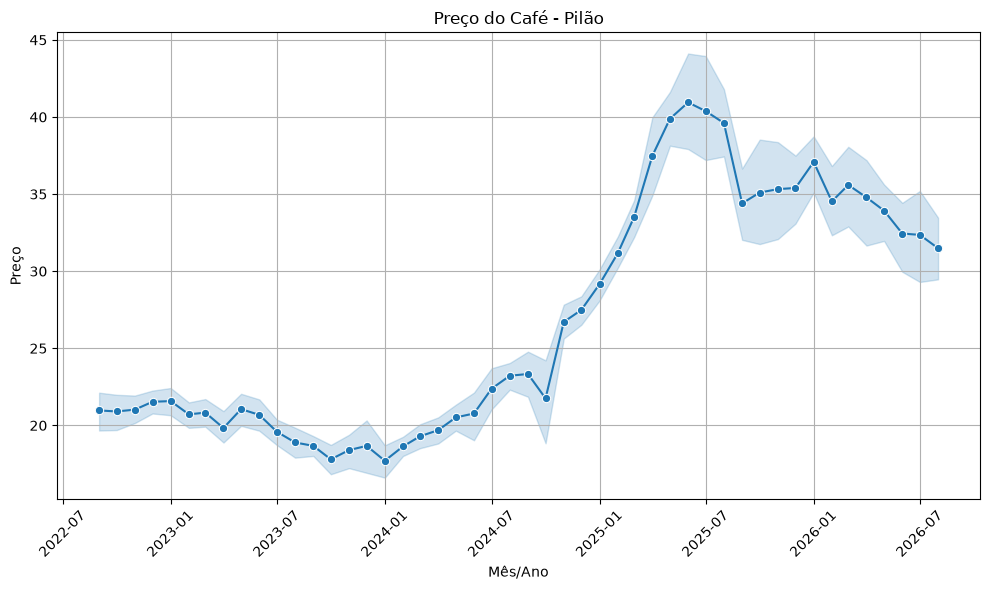

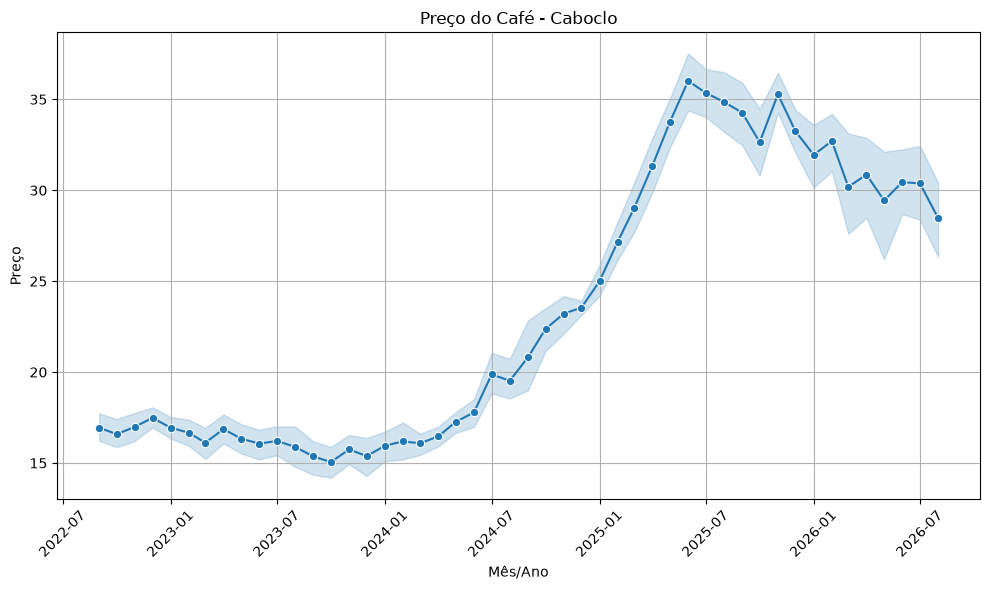

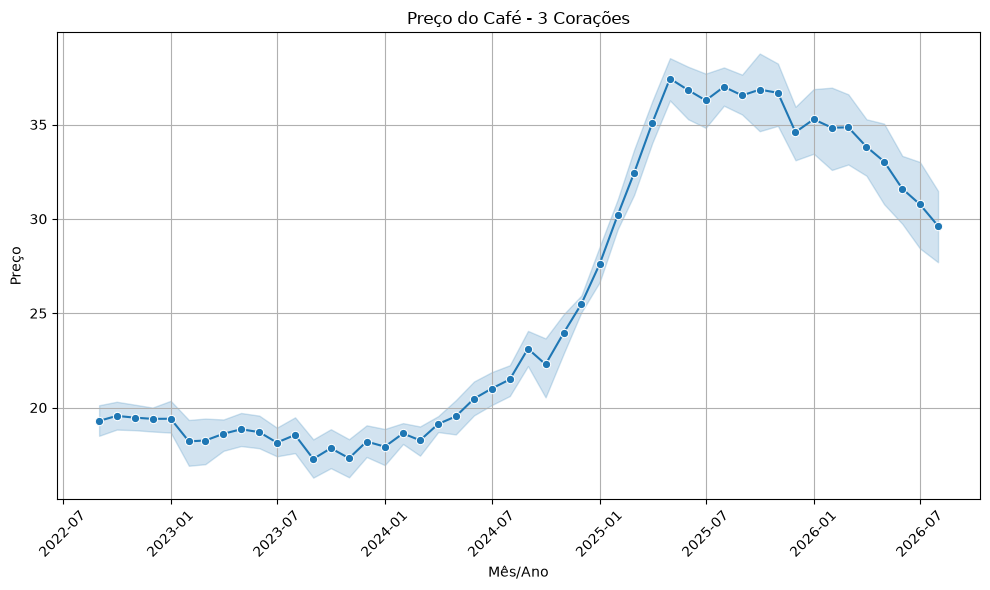

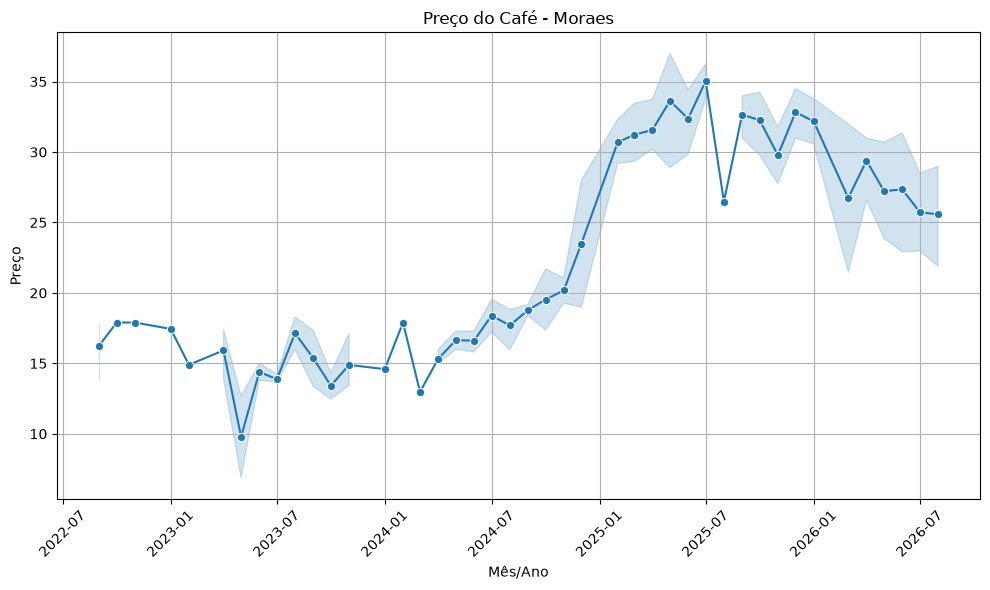

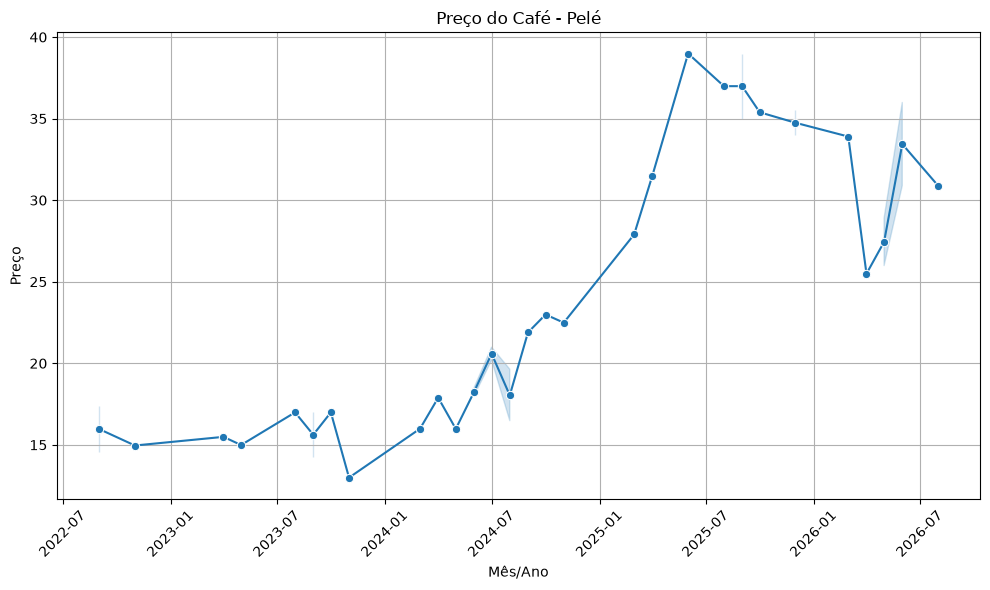

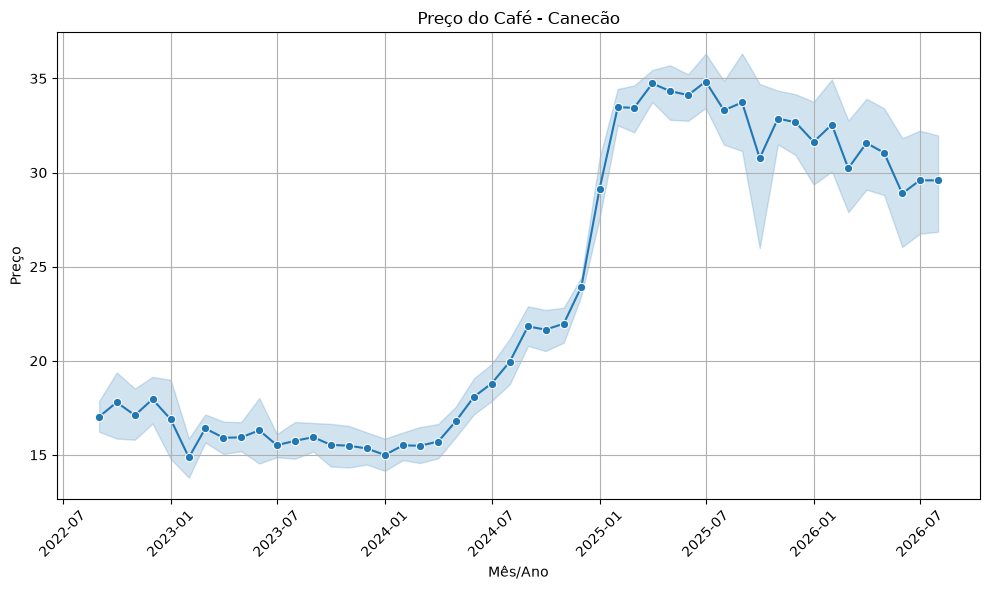

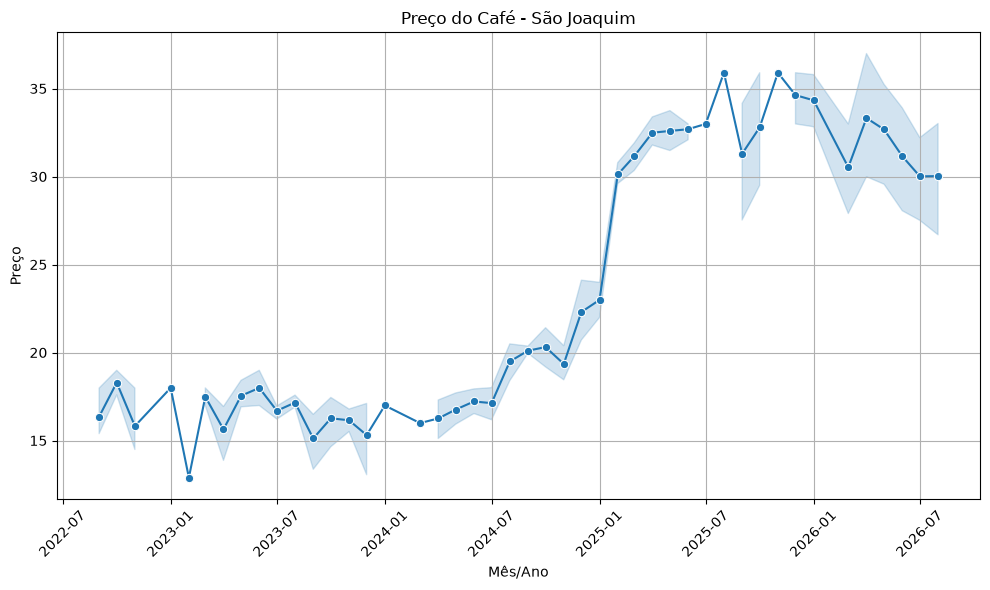

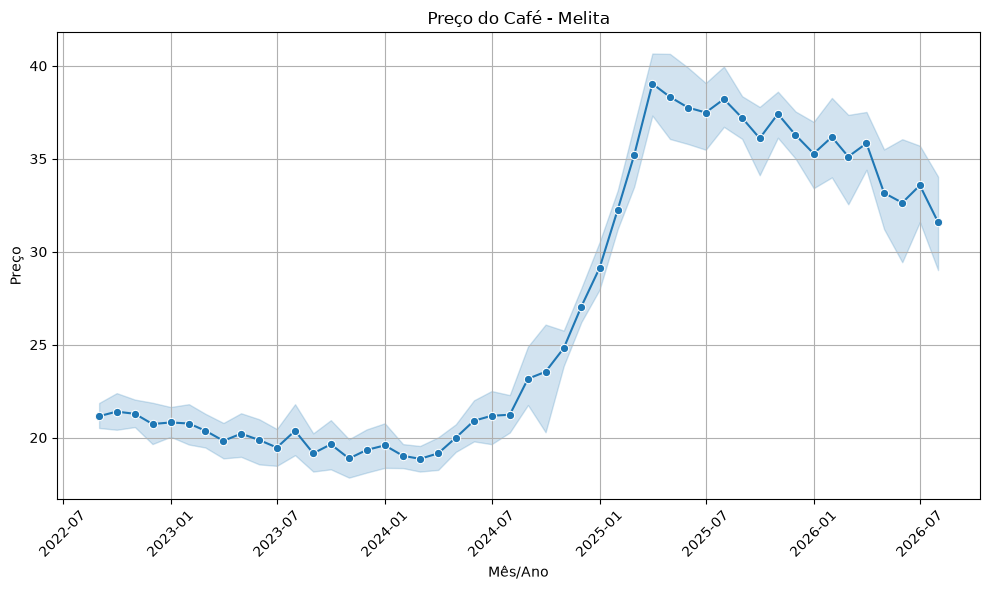

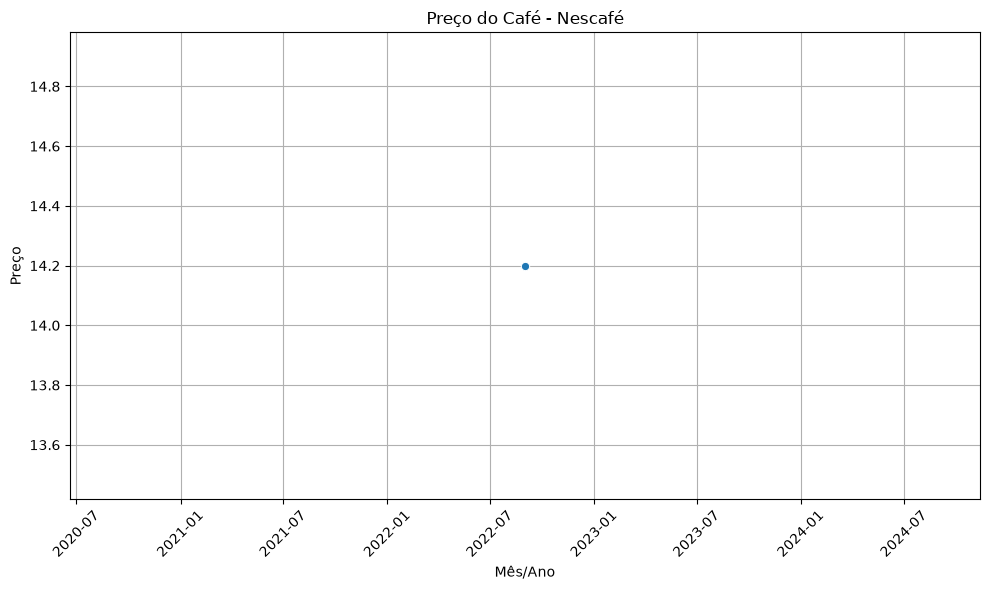

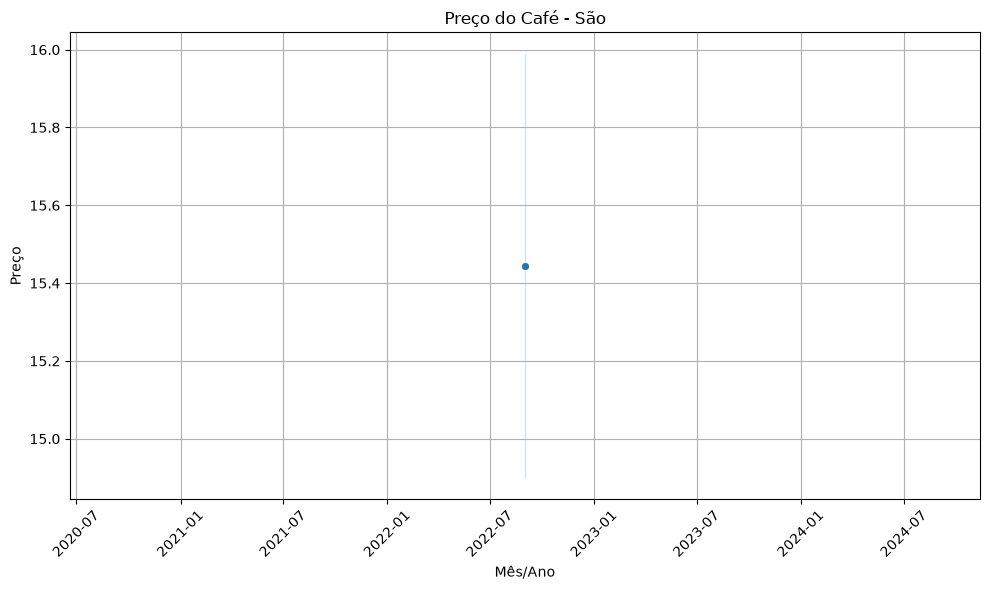

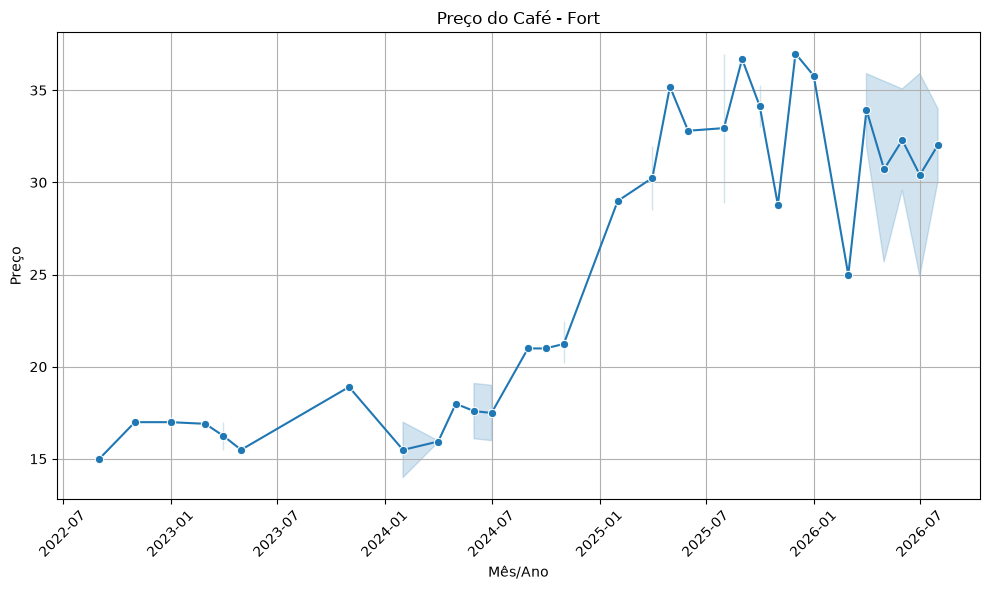

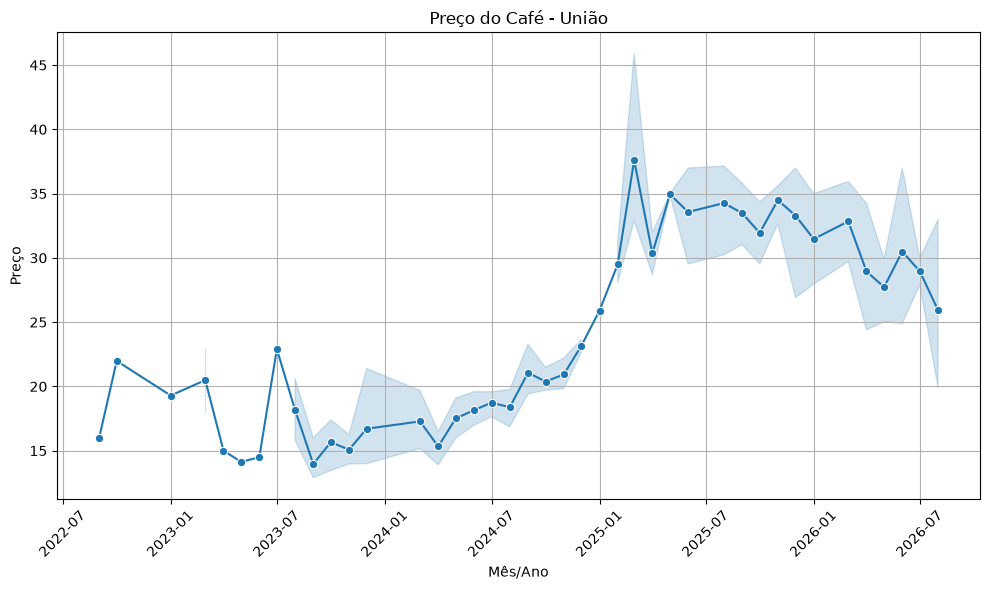

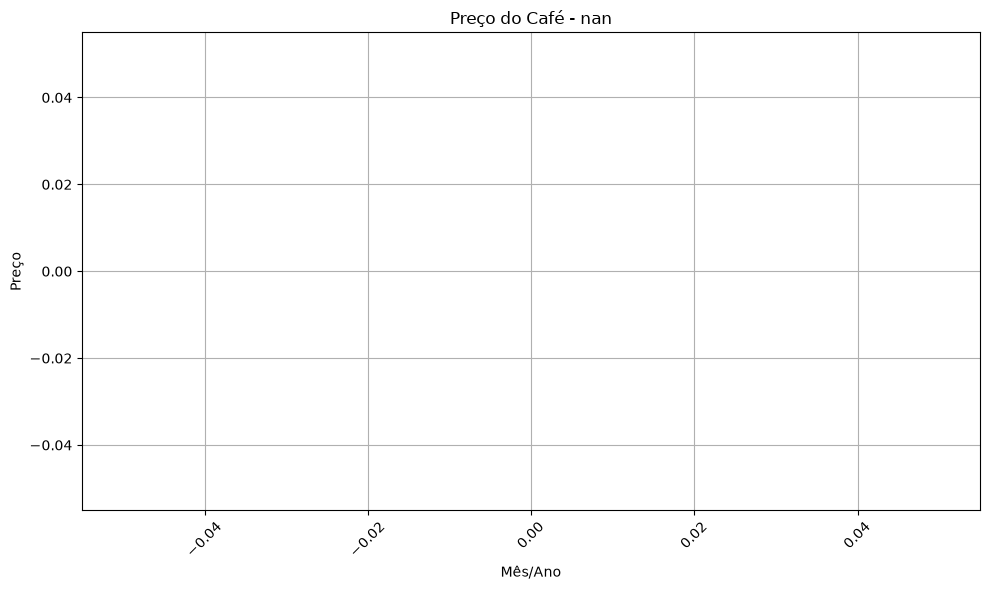

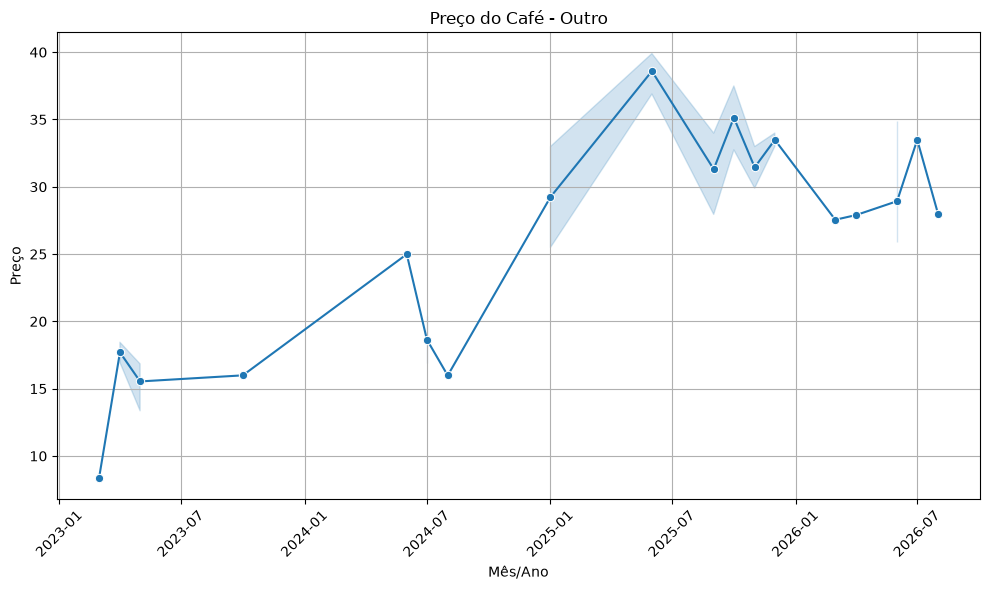

In [25]:
plotar_grafico_por_cada_marca(df_cafe, df_cafe['Marca'].unique())

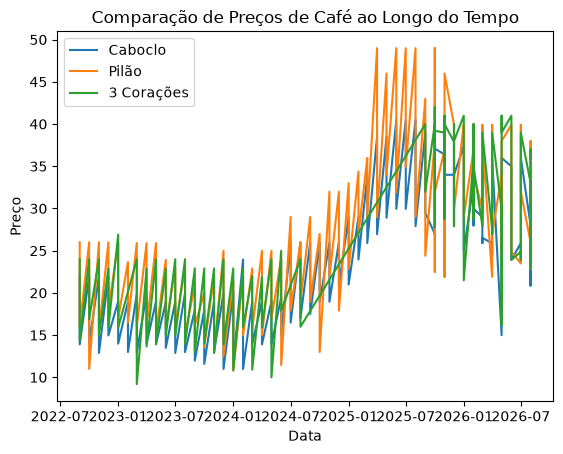

In [12]:
plt.plot(df_caboclo['Mes_Ano_Data'], df_caboclo['Preco'], label='Caboclo')
plt.plot(df_pilao['Mes_Ano_Data'], df_pilao['Preco'], label='Pilão')
plt.plot(df_3coracoes['Mes_Ano_Data'], df_3coracoes['Preco'], label='3 Corações')
plt.title('Comparação de Preços de Café ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Preço')
plt.legend()
plt.show()

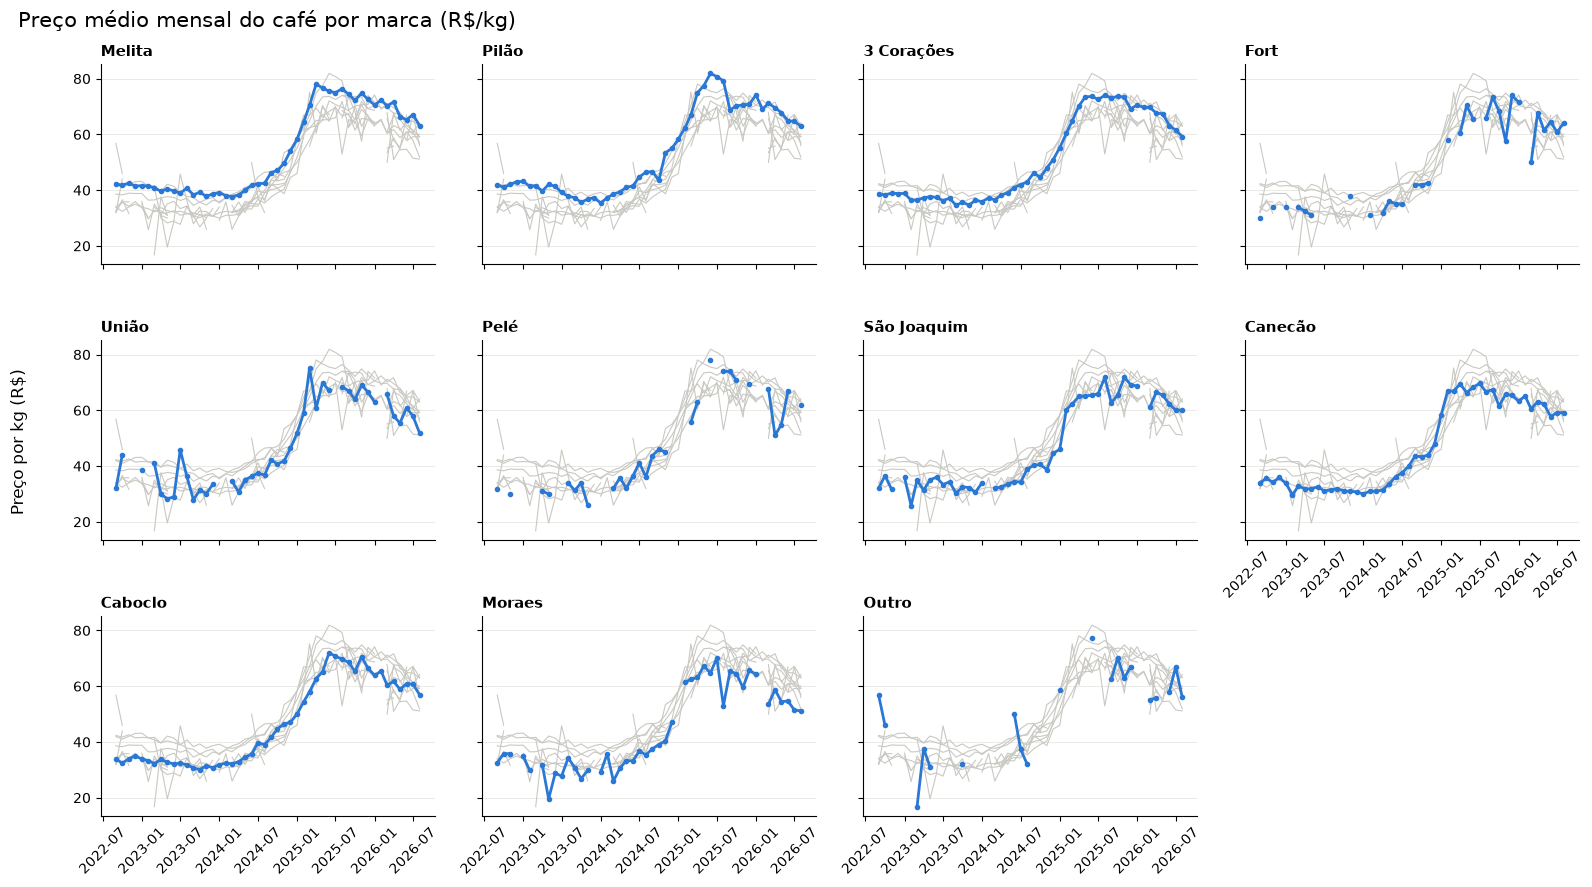

In [13]:
# Padroniza os nomes das marcas (espaços sobrando, maiúsculas/minúsculas, registros incompletos)
marca = df_cafe['Marca'].str.strip().str.title()
marca = marca.replace({'São': 'São Joaquim', 'Nescafé': 'Outro'}).fillna('Outro')

# Média mensal do preço por kg (PPK) de cada marca: uma coluna por marca, uma linha por mês
cafe_mensal = (
    df_cafe.assign(Marca=marca)
    .groupby(['Mes_Ano_Data', 'Marca'])['PPK']
    .mean()
    .unstack('Marca')
)

# Ordena da marca mais cara para a mais barata, deixando "Outro" por último
ordem = cafe_mensal.drop(columns='Outro').mean().sort_values(ascending=False).index.tolist() + ['Outro']

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for ax, nome in zip(axes.flat, ordem):
    # Todas as marcas em cinza como referência, com a marca do painel em destaque
    ax.plot(cafe_mensal.index, cafe_mensal, color='#c9c8c2', linewidth=0.8)
    ax.plot(cafe_mensal.index, cafe_mensal[nome], color='#2a78d6', linewidth=2, marker='o', markersize=3)
    ax.set_title(nome, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', color='#e8e7e2', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', rotation=45)

# Remove os painéis que sobraram na grade e devolve o eixo de datas ao painel logo acima
for ax in axes.flat[len(ordem):]:
    ax.remove()
axes[1, 3].tick_params(axis='x', labelbottom=True)

fig.suptitle('Preço médio mensal do café por marca (R$/kg)', x=0.01, ha='left', fontsize=15)
fig.supylabel('Preço por kg (R$)', x=0.005)
fig.tight_layout(rect=(0.015, 0, 1, 1))
plt.show()